# 🌐 Tema 6.3: Grafos Multiplex (Múltiples Relaciones)
Ejemplo didáctico: La Vida Universitaria.

### 1. El Problema del Grafo Simple (`nx.Graph`)
Intentemos modelar a dos estudiantes (Ana y Beto) que son compañeros de proyecto, pero que también juegan Valorant juntos en las noches.

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

# Usamos el grafo tradicional que conocemos
G_simple = nx.Graph()

# Añadimos la relación académica
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')

# Añadimos la relación de gaming
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')

print("Aristas en el grafo simple:")
print(G_simple.edges(data=True))

Aristas en el grafo simple:
[('Ramiro', 'Cristobal', {'relacion': 'Clash Royale'})]


### 2. La Solución: MultiGraph (El Grafo Multicapa)
Para modelar la complejidad humana, usamos `nx.MultiGraph`, que permite múltiples aristas paralelas entre los mismos dos nodos.

In [8]:
# Instanciamos un Multigrafo
MG = nx.MultiGraph()

# Poblamos nuestro microcosmos universitario
MG.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')
MG.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')
MG.add_edge('Beto', 'Carlos', relacion='Roomies')
MG.add_edge('Beto', 'Carlos', relacion='Clash Royale')
MG.add_edge('Carlos', 'Dani', relacion='Proyecto Final')

print("\n--- Todas las relaciones entre Ramiro y Cristobal ---")
display(MG['Ramiro']['Cristobal'])

print("\nNodos totales:", MG.number_of_nodes())
print("Aristas totales:", MG.number_of_edges())


--- Todas las relaciones entre Ramiro y Cristobal ---


AtlasView({0: {'relacion': 'Proyecto Final'}, 1: {'relacion': 'Clash Royale'}})


Nodos totales: 5
Aristas totales: 5


### 3. Diseccionando el Grafo (Slicing)
Si queremos saber quién es el mejor jugando Valorant, la relación de 'Roomies' o 'Proyecto' solo nos hace ruido. Debemos extraer (rebanar) esa capa específica.

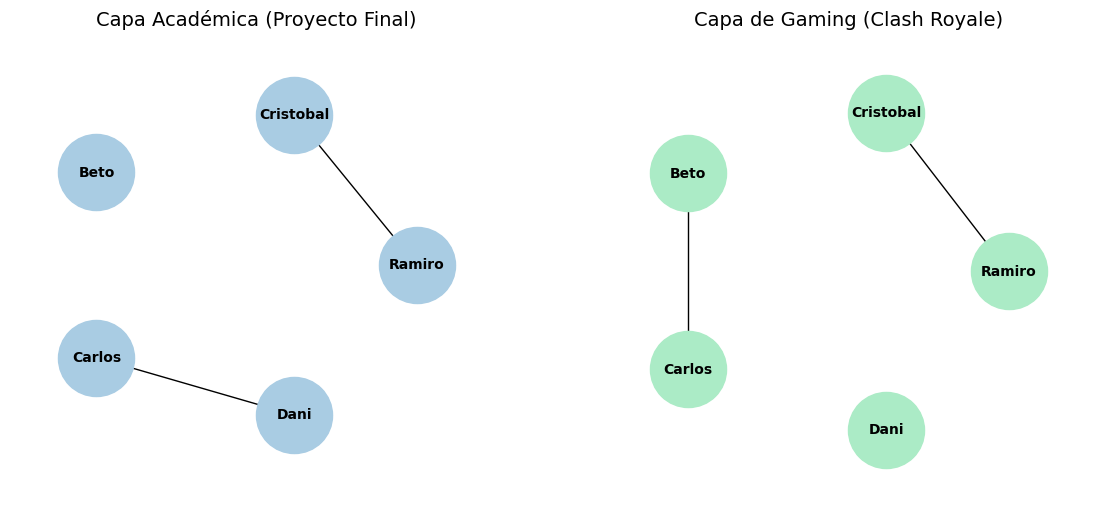

In [9]:
# Extraemos las capas
aristas_academicas = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Proyecto Final']
G_academico = nx.Graph()
G_academico.add_nodes_from(MG.nodes()) # Aseguramos que todos los nodos existan aunque no tengan aristas aquí
G_academico.add_edges_from(aristas_academicas)

aristas_gaming = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Clash Royale']
G_gaming = nx.Graph()
G_gaming.add_nodes_from(MG.nodes())
G_gaming.add_edges_from(aristas_gaming)

# 🛠️ EL TRUCO VISUAL PARA MULTIGRAFOS: 
# Calculamos la posición (pos) UNA SOLA VEZ basándonos en los 4 nodos. 
# circular_layout los pone en un cuadrado perfecto, evitando que se aglomeren.
pos_fija = nx.circular_layout(MG)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
# Usamos la 'pos_fija' y ajustamos márgenes para que los nodos no se corten en los bordes
nx.draw(G_academico, pos_fija, with_labels=True, node_color='#A9CCE3', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa Académica (Proyecto Final)', fontsize=14)
plt.margins(0.2) # Da un 20% de espacio extra en los bordes

plt.subplot(1, 2, 2)
nx.draw(G_gaming, pos_fija, with_labels=True, node_color='#ABEBC6', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa de Gaming (Clash Royale)', fontsize=14)
plt.margins(0.2)

plt.show()

### Fase 1: Data Engineering


In [10]:
import json
import pandas as pd

with open('dataset/api_troll_farm.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

retweets = []
for item in data:
    origen = item.get('account_id')
    actividad = item.get('activity')
    if origen and actividad and actividad.get('retweets'):
        for destino in actividad['retweets']:
            if destino and origen.lower() != destino.lower():
                retweets.append({
                    'Origen': origen.lower(),
                    'Destino': destino.lower(),
                    'Relacion': 'Retweet'
                })

df_social = pd.DataFrame(retweets)

metadatos = []
for item in data:
    usuario = item.get('account_id')
    meta = item.get('metadata')
    if usuario and meta:
        metadatos.append({
            'Usuario': usuario.lower(),
            'IP': meta.get('last_ip'),
            'Tarjeta': meta.get('payment_hash')
        })

df_meta = pd.DataFrame(metadatos).drop_duplicates()
df_meta_tarjeta = df_meta.dropna(subset=['Tarjeta'])

merged = pd.merge(df_meta_tarjeta, df_meta_tarjeta, on='Tarjeta')
merged = merged[merged['Usuario_x'] < merged['Usuario_y']]

df_infra = pd.DataFrame({
    'Origen': merged['Usuario_x'],
    'Destino': merged['Usuario_y'],
    'Relacion': 'Misma_Tarjeta'
})

df_maestro = pd.concat([df_social, df_infra], ignore_index=True)
display(df_maestro)

,Origen,Destino,Relacion
0,troll_bot_1,real_user_11,Retweet
1,real_user_14,real_user_15,Retweet
2,real_user_14,real_user_11,Retweet
3,real_user_13,real_user_3,Retweet
4,real_user_13,real_user_9,Retweet
5,troll_bot_5,real_user_12,Retweet
6,troll_bot_5,troll_bot_1,Retweet
7,real_user_12,real_user_15,Retweet
8,real_user_11,real_user_14,Retweet
9,real_user_11,real_user_6,Retweet


### Fase 2: El Grafo Multicapa 

In [11]:
import networkx as nx

MG = nx.from_pandas_edgelist(
    df_maestro,
    source='Origen',
    target='Destino',
    edge_attr='Relacion',
    create_using=nx.MultiDiGraph()
)

print("Nodos totales:", MG.number_of_nodes())
print("Aristas totales:", MG.number_of_edges())

Nodos totales: 21
Aristas totales: 52


### Fase 3: El Slicing

In [12]:
aristas_tarjeta = [(u, v) for u, v, d in MG.edges(data=True) if d.get('Relacion') == 'Misma_Tarjeta']

G_tarjeta = nx.Graph()
G_tarjeta.add_edges_from(aristas_tarjeta)

tribus = list(nx.connected_components(G_tarjeta))
for tribu in tribus:
    print("Tribu coludida financieramente:", tribu)

Tribu coludida financieramente: {'troll_bot_2', 'troll_bot_4', 'troll_bot_6', 'troll_bot_5', 'troll_bot_3', 'troll_bot_1'}


### Veredicto Final
1. ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?

6 bots fueron identificados como fraudulentos, estos siendo:
"TROLL_BOT_1", "TROLL_BOT_2", "TROLL_BOT_3", "TROLL_BOT_4", "TROLL_BOT_5" Y "TROLL_BOT_6",

2. ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?

El hash de pago compartido por toda la red de bots es:
VISA-4455-XXXX-9090

3. Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?

Usando la ingenieria de caracteristicas de grafos, agregando nuevas columas por usuario, estas columnas siendo:

* shared_card_flag: 1 si la cuenta comparte tarjeta con otro usuario, o 0 si no
* cluster_size: Siendo el tamaño del componente financiero al que pertenece la cuenta
* degree_tarjeta: La cantidad directa de otros usuarios con los que comparte el mismo metodo de pago
